# Coordination-test on Macaque data


The dataset used here can be obtained from https://doi.org/10.6080/K0B27SHN

In [ ]:
# load necessary packages
from zipfile import ZipFile
from pathlib import Path
import os
import pandas as pd
from io import BytesIO
from scipy.io import loadmat
from utils import*


There are 5 mat files corresponding to 5 sessions:

In [ ]:
zip_path = Path("Datasets/CRCNS/v1-v2_gratings.zip") # fill this path yourself

with ZipFile(zip_path, "r") as archive:
    for info in archive.infolist():
        print(
            info.filename,
            f"{info.file_size} bytes",
            "directory" if info.is_dir() else "file",
        )

v1-v2_gratings/ 0 bytes directory
v1-v2_gratings/mat_neural_data/ 0 bytes directory
v1-v2_gratings/mat_neural_data/106r002p70.mat 15505921 bytes file
v1-v2_gratings/mat_neural_data/105l001p16.mat 34774439 bytes file
v1-v2_gratings/mat_neural_data/107l003p143.mat 38843972 bytes file
v1-v2_gratings/mat_neural_data/106r001p26.mat 29213463 bytes file
v1-v2_gratings/mat_neural_data/107l002p67.mat 34004346 bytes file
v1-v2_gratings/software/ 0 bytes directory
v1-v2_gratings/software/COLOR_MAP.mat 395 bytes file
v1-v2_gratings/software/Squash.m 90 bytes file
v1-v2_gratings/software/SET_CONSTS.m 108 bytes file
v1-v2_gratings/software/BinTime.m 649 bytes file
v1-v2_gratings/software/ExtractSpikes.m 2810 bytes file
v1-v2_gratings/software/example.m 1402 bytes file
v1-v2_gratings/startup.m 61 bytes file


## load data from one of the sessions

In [ ]:


# session = "v1-v2_gratings/mat_neural_data/106r002p70.mat" 
# session = "v1-v2_gratings/mat_neural_data/105l001p16.mat" 
# session = "v1-v2_gratings/mat_neural_data/107l003p143.mat" 
# session = "v1-v2_gratings/mat_neural_data/106r001p26.mat" 
session = "v1-v2_gratings/mat_neural_data/107l002p67.mat" 


with ZipFile(zip_path) as archive:
    mat = loadmat(
        BytesIO(archive.read(session)),
        simplify_cells=True,
    )

neural = mat["neuralData"]
print(neural.keys())

dict_keys(['spikeRasters', 'stim', 'trialId', 'unitCodes', 'rfInfo'])


In [5]:
print(neural.keys())
print("Number of trials:", len(neural["stim"]))
print("Stimulus IDs:", neural["stim"])

dict_keys(['spikeRasters', 'stim', 'trialId', 'unitCodes', 'rfInfo'])
Number of trials: 6400
Stimulus IDs: [3 0 7 ... 0 3 0]


 there are 9 stimulus IDs; each corresponding to oriented-grating stimulus with a certain orientation angle:

In [12]:
print("Unique Stimulus IDs:", set(neural["stim"]))

Unique Stimulus IDs: {0, 1, 2, 3, 4, 5, 6, 7, 8}


# code to fetch data from v1, v2 regions or both

In [13]:
def trial_to_v1_raster(trial_index):
    rasters = neural["spikeRasters"]
    v1_rasters = rasters[:, 0]
    v1_raster = v1_rasters[trial_index]
    v1_dense = v1_raster.toarray()
    return v1_dense

def trial_to_v2_raster(trial_index):
    rasters = neural["spikeRasters"]
    v2_rasters = rasters[:, 1]
    v2_raster = v2_rasters[trial_index]
    v2_dense = v2_raster.toarray()
    return v2_dense

def trial_to_raster(trial_index):
    # concatenate v1 and v2 rasters along the neuron axis
    v1_raster = trial_to_v1_raster(trial_index)
    v2_raster = trial_to_v2_raster(trial_index)
    return np.concatenate([v1_raster, v2_raster], axis=0)

all_shapes = [trial_to_v1_raster(i).shape for i in range(len(neural["stim"]))]
all_shapes[:10]



[(97, 1280),
 (97, 1500),
 (97, 1280),
 (97, 1500),
 (97, 1280),
 (97, 1500),
 (97, 1280),
 (97, 1500),
 (97, 1280),
 (97, 1500)]

Above shapes indicate (Number of Neurons, Total Recording Time) in v1 region

In [14]:
all_shapes_v2 = [trial_to_v2_raster(i).shape for i in range(len(neural["stim"]))]

all_shapes_v2[:10] 


[(31, 1280),
 (31, 1500),
 (31, 1280),
 (31, 1500),
 (31, 1280),
 (31, 1500),
 (31, 1280),
 (31, 1500),
 (31, 1280),
 (31, 1500)]

Above shapes indicate (Number of Neurons, Total Recording Time) in v2 region

# Randomly select 100 genuine rasters

As explained in the manuscript, we fix a stimulus, and randomly select 100 simultaneously recorded rasters for that stimulus. We refer to these rasters as **genuine rasters**.

In [15]:
def fetch_data(
    neural,
    stimulus,
    n_trials=100,
    area="both",
    random_state=42,
):
    """
    Randomly select genuine trials for one stimulus.

    Parameters
    ----------
    neural : dict
        The neuralData dictionary loaded from the CRCNS file.

    stimulus : int
        Stimulus label to retrieve, such as 1, 2, ..., 8.
        Stimulus 0 is the blank-screen condition.

    n_trials : int
        Number of genuine trials to select.

    area : str
        "V1", "V2", or "both".

    random_state : int
        Random seed, allowing the same trials to be selected again.

    Returns
    -------
    dict with:
        "rasters"       : selected population rasters
        "labels"        : stimulus label for each raster
        "trial_indices" : row positions in neuralData
        "trial_ids"     : recorded experimental trial IDs
        "stimulus"      : requested stimulus
        "area"          : requested neural population
    """

    stimulus_labels = np.asarray(
        neural["stim"]
    ).reshape(-1)

    trial_ids = np.asarray(
        neural["trialId"]
    ).reshape(-1)

    # Find every trial having the requested stimulus.
    available_indices = np.flatnonzero(
        stimulus_labels == stimulus
    )

    if len(available_indices) == 0:
        raise ValueError(
            f"No trials found for stimulus {stimulus}."
        )

    if n_trials > len(available_indices):
        raise ValueError(
            f"Stimulus {stimulus} has only "
            f"{len(available_indices)} trials, "
            f"but {n_trials} were requested."
        )

    # Select genuine trials without replacement.
    rng = np.random.default_rng(random_state)

    selected_indices = rng.choice(
        available_indices,
        size=n_trials,
        replace=False,
    )

    # Sorting makes the returned trial order easier to inspect.
    selected_indices = np.sort(selected_indices)

    area = area.upper()
    rasters = []

    for trial_index in selected_indices:

        if area == "V1":
            raster = neural["spikeRasters"][
                trial_index, 0
            ].toarray()

        elif area == "V2":
            raster = neural["spikeRasters"][
                trial_index, 1
            ].toarray()

        elif area == "BOTH":
            v1_raster = neural["spikeRasters"][
                trial_index, 0
            ].toarray()

            v2_raster = neural["spikeRasters"][
                trial_index, 1
            ].toarray()

            # Neurons form the rows, so combine along axis 0.
            raster = np.concatenate(
                [v1_raster, v2_raster],
                axis=0,
            )

        else:
            raise ValueError(
                'area must be "V1", "V2", or "both".'
            )

        # Store spike rasters compactly as zeros and ones.
        rasters.append(
            raster.astype(np.uint8, copy=False)
        )

    # Confirm that every selected raster has the same dimensions.
    raster_shapes = {
        raster.shape for raster in rasters
    }

    if len(raster_shapes) != 1:
        raise ValueError(
            f"Selected rasters have different shapes: "
            f"{raster_shapes}"
        )

    return {
        "rasters": rasters,
        "labels": np.full(
            n_trials,
            stimulus,
            dtype=int,
        ),
        "trial_indices": selected_indices,
        "trial_ids": trial_ids[selected_indices],
        "stimulus": stimulus,
        "area": area,
    }

Here's an example plot; one randomly chosen among the 100.

Number of rasters: 100
Shape of each raster: (128, 1280)
First five trial IDs: [253 345 377 427 453]


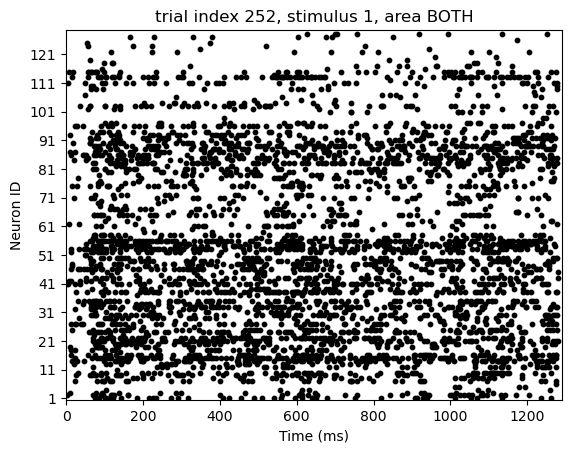

In [16]:
stimulus_data = fetch_data(
    neural=neural,
    stimulus=1,
    n_trials=100,
    area="both",
    random_state=42,
)

real_rasters = stimulus_data["rasters"]

print(
    "Number of rasters:",
    len(real_rasters),
)

print(
    "Shape of each raster:",
    real_rasters[0].shape,
)

print(
    "First five trial IDs:",
    stimulus_data["trial_ids"][:5],
)


ex_index = 0
raster_ex = real_rasters[ex_index]
trial_index = stimulus_data["trial_indices"][ex_index]

fig, ax = plt.subplots()

plot_raster(raster_ex,axes=ax)

plt.yticks(np.arange(0,raster_ex.shape[0],10))

ax.set_title(f"trial index {trial_index}, stimulus {stimulus_data['stimulus']}, area {stimulus_data['area']}")

plt.show()

# split genuine data into 20 splits: each split is 70:30 train/test

We split the genuine rasters into 70:30 train/test sets.

In [17]:
import numpy as np
from sklearn.model_selection import ShuffleSplit


def split_data(
    stimulus_data,
    training_size=0.70,
    n_splits=20,
    random_state=42,
):
    """
    Create repeated random training/test splits.

    Parameters
    ----------
    stimulus_data : dict
        Output returned by fetch_data().

    training_size : float
        Fraction assigned to training. For example, 0.70 gives
        70 training and 30 test rasters when there are 100 rasters.

    n_splits : int
        Number of random training/test splits.

    random_state : int
        Random seed for reproducible splits.

    Returns
    -------
    list of dictionaries
        Each dictionary contains the training and test rasters,
        trial indices, and recorded trial IDs for one split.
    """

    if not 0 < training_size < 1:
        raise ValueError(
            "training_size must be between 0 and 1."
        )

    if n_splits < 1:
        raise ValueError(
            "n_splits must be at least 1."
        )

    rasters = stimulus_data["rasters"]
    trial_indices = np.asarray(
        stimulus_data["trial_indices"]
    )
    trial_ids = np.asarray(
        stimulus_data["trial_ids"]
    )

    n_rasters = len(rasters)

    if n_rasters < 2:
        raise ValueError(
            "At least two rasters are required."
        )

    splitter = ShuffleSplit(
        n_splits=n_splits,
        train_size=training_size,
        random_state=random_state,
    )

    splits = []

    # positions refer to positions within stimulus_data:
    # 0, 1, ..., n_rasters - 1
    for split_number, (
        train_positions,
        test_positions,
    ) in enumerate(
        splitter.split(np.arange(n_rasters)),
        start=1,
    ):
        train_rasters = [
            rasters[position]
            for position in train_positions
        ]

        test_rasters = [
            rasters[position]
            for position in test_positions
        ]

        split = {
            "split": split_number,

            "train_rasters": train_rasters,
            "test_rasters": test_rasters,

            "train_positions": train_positions,
            "test_positions": test_positions,

            "train_trial_indices": (
                trial_indices[train_positions]
            ),
            "test_trial_indices": (
                trial_indices[test_positions]
            ),

            "train_trial_ids": (
                trial_ids[train_positions]
            ),
            "test_trial_ids": (
                trial_ids[test_positions]
            ),
        }

        splits.append(split)

    return splits

In [18]:
splits = split_data(
    stimulus_data,
    training_size=0.70,
    n_splits=20,
    random_state=42,
)

# code to generate shuffled data from a given set of genuine rasters

In [9]:
def generate_shuffled_data(
    real_rasters,
    random_state=42,
):
    """
    Generate one shuffled raster for every real raster.

    Each neuron's spike trains are randomly rearranged across trials.
    This preserves the neuron's collection of spike trains while
    disrupting the original simultaneous population grouping.

    Parameters
    ----------
    real_rasters : list of arrays
        Genuine rasters from one training or test partition.

    random_state : int
        Random seed for reproducibility.

    Returns
    -------
    dict containing:
        shuffled_rasters
            Generated shuffled rasters.

        donor_positions
            For every shuffled and neuron, the position of the
            real raster supplying that neuron's spike train.
    """

    n_trials = len(real_rasters)

    if n_trials < 2:
        raise ValueError(
            "At least two real rasters are required."
        )

    # Confirm that all rasters have identical dimensions.
    raster_shapes = {
        raster.shape for raster in real_rasters
    }

    if len(raster_shapes) != 1:
        raise ValueError(
            f"Real rasters have different shapes: "
            f"{raster_shapes}"
        )

    # Shape:
    # trials × neurons × time
    real_array = np.stack(real_rasters)

    n_trials, n_neurons, _ = real_array.shape

    rng = np.random.default_rng(random_state)

    shuffled_array = np.empty_like(real_array)

    # This records the donor trial position for every neuron.
    donor_positions = np.empty(
        (n_trials, n_neurons),
        dtype=int,
    )

    original_positions = np.arange(n_trials)

    for neuron in range(n_neurons):

        # Generate a permutation with no unchanged positions.
        while True:
            permutation = rng.permutation(n_trials)

            if np.all(
                permutation != original_positions
            ):
                break

        donor_positions[:, neuron] = permutation

        shuffled_array[:, neuron, :] = (
            real_array[
                permutation,
                neuron,
                :,
            ]
        )

    shuffled_rasters = [
        shuffled_array[index]
        for index in range(n_trials)
    ]

    return {
        "shuffled_rasters": shuffled_rasters,
        "donor_positions": donor_positions,
    }

## Example genuine vs shuffled raster

GENUINE RASTER
----------------
CRCNS archive entry: 107l002p67
Session name:        107l002p67
Stimulus:            1
Selected position:   0
Dataset row index:   252
Recorded trial ID:   253
Brain area:          BOTH
V1 neurons:          97
V2 neurons:          31
Total neurons:       128
Time bins:           1280
Total spikes:        3987

SHUFFLED RASTER
----------------
Construction: each neuron's complete spike train was taken from another genuine trial having the same session and stimulus.
Session name:        107l002p67
Stimulus:            1
Shape:               (128, 1280)
Total spikes:        3648
Unique donor trials: 68
Original position used as its own donor: False

First 10 neuron donor details:
Neuron   1: dataset row 1948, recorded trial ID 1949
Neuron   2: dataset row 4200, recorded trial ID 4201
Neuron   3: dataset row 344, recorded trial ID 345
Neuron   4: dataset row 4898, recorded trial ID 4899
Neuron   5: dataset row 1496, recorded trial ID 1497
Neuron   6: dataset

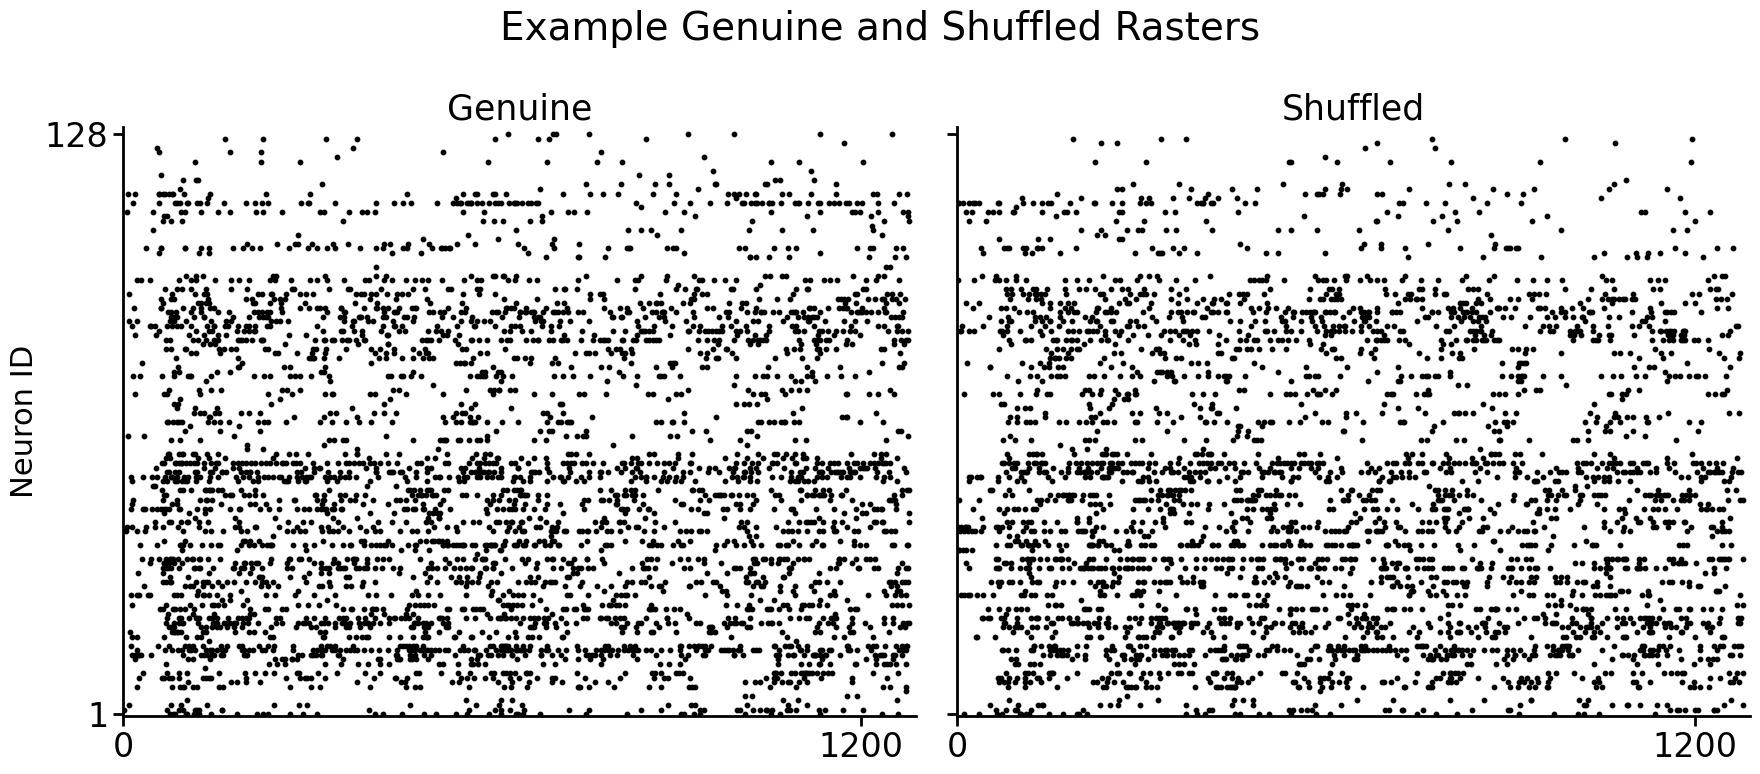


Saved: Results_Coordination_test/results_107l002p67/107l002p67_example_genuine_and_shuffled_rasters.pdf


In [92]:
# ------------------------------------------------------------
# Example settings
# ------------------------------------------------------------

stimulus = 1
example_position = 0
n_trials = 100
data_random_state = 42
shuffle_random_state = 43

session_name = Path(session).stem

# ------------------------------------------------------------
# Fetch genuine rasters
# ------------------------------------------------------------

stimulus_data = fetch_data(
    neural=neural,
    stimulus=stimulus,
    n_trials=n_trials,
    area="both",
    random_state=data_random_state,
)

genuine_rasters = stimulus_data["rasters"]

# Shuffle across the same 100 genuine trials.
shuffled_data = generate_shuffled_data(
    genuine_rasters,
    random_state=shuffle_random_state,
)

shuffled_rasters = shuffled_data["shuffled_rasters"]

genuine_raster = genuine_rasters[example_position]
shuffled_raster = shuffled_rasters[example_position]

# ------------------------------------------------------------
# Identify where the genuine raster came from
# ------------------------------------------------------------

trial_index = stimulus_data["trial_indices"][example_position]
trial_id = stimulus_data["trial_ids"][example_position]

v1_neurons = neural["spikeRasters"][trial_index, 0].shape[0]
v2_neurons = neural["spikeRasters"][trial_index, 1].shape[0]

# Each shuffled neuron's spike train has a donor trial.
donor_positions = shuffled_data["donor_positions"][example_position]
donor_trial_indices = stimulus_data["trial_indices"][donor_positions]
donor_trial_ids = stimulus_data["trial_ids"][donor_positions]

# ------------------------------------------------------------
# Print descriptive details
# ------------------------------------------------------------

print("GENUINE RASTER")
print("----------------")
print(f"CRCNS archive entry: {session}")
print(f"Session name:        {session_name}")
print(f"Stimulus:            {stimulus}")
print(f"Selected position:   {example_position}")
print(f"Dataset row index:   {trial_index}")
print(f"Recorded trial ID:   {trial_id}")
print(f"Brain area:          {stimulus_data['area']}")
print(f"V1 neurons:          {v1_neurons}")
print(f"V2 neurons:          {v2_neurons}")
print(f"Total neurons:       {genuine_raster.shape[0]}")
print(f"Time bins:           {genuine_raster.shape[1]}")
print(f"Total spikes:        {genuine_raster.sum()}")

print("\nSHUFFLED RASTER")
print("----------------")
print(
    "Construction: each neuron's complete spike train was taken "
    "from another genuine trial having the same session and stimulus."
)
print(f"Session name:        {session_name}")
print(f"Stimulus:            {stimulus}")
print(f"Shape:               {shuffled_raster.shape}")
print(f"Total spikes:        {shuffled_raster.sum()}")
print(f"Unique donor trials: {len(np.unique(donor_trial_ids))}")
print(
    "Original position used as its own donor:",
    bool(np.any(donor_positions == example_position)),
)

print("\nFirst 10 neuron donor details:")
for neuron in range(min(10, genuine_raster.shape[0])):
    print(
        f"Neuron {neuron + 1:3d}: "
        f"dataset row {donor_trial_indices[neuron]}, "
        f"recorded trial ID {donor_trial_ids[neuron]}"
    )

# ------------------------------------------------------------
# Plot side by side
# ------------------------------------------------------------

plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 25,
    "axes.labelsize": 22,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
    "figure.titlesize": 28,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8),
    sharex=True,
    sharey=True,
)

plot_raster(
    genuine_raster,
    axes=axes[0],
)

plot_raster(
    shuffled_raster,
    axes=axes[1],
)

axes[0].set_title("Genuine")
axes[1].set_title("Shuffled")
n_neurons = genuine_raster.shape[0]
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(False)
    ax.spines["left"].set_linewidth(2)
    ax.spines["bottom"].set_linewidth(2)
    ax.tick_params(width=2, length=7)
    ax.set_xticks([0,1200])
    ax.set_yticks([0, n_neurons-1])
    ax.set_yticklabels([1, n_neurons])

axes[0].set_ylabel("Neuron ID")

fig.suptitle("Example Genuine and Shuffled Rasters")
fig.tight_layout()

# Optional PDF output
output_directory = (
    Path("Results_Coordination_test")
    / f"results_{session_name}"
)
output_directory.mkdir(parents=True, exist_ok=True)

output_file = (
    output_directory
    / f"{session_name}_example_genuine_and_shuffled_rasters.pdf"
)

fig.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight",
)

plt.show()

print(f"\nSaved: {output_file}")

## code to run TDA on a split

In [19]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
)
from tqdm.auto import tqdm


def run_tda_on_split(
    training_real,
    training_shuffled,
    testing_real,
    testing_shuffled,
    q=3.0,
    random_state=42,
):
    """
    Run H0 TDA 1-nearest-neighbor classification on one
    fixed training/test split.

    Labels
    ------
    1 = genuine
    0 = shuffled
    """

    # --------------------------------------------------
    # Build the training data and labels
    # --------------------------------------------------

    training_rasters = (
        list(training_real)
        + list(training_shuffled)
    )

    training_labels = np.concatenate([
        np.ones(
            len(training_real),
            dtype=int,
        ),
        np.zeros(
            len(training_shuffled),
            dtype=int,
        ),
    ])

    # Shuffle the training order so ties are not affected
    # systematically by genuine rasters appearing first.
    rng = np.random.default_rng(random_state)

    training_order = rng.permutation(
        len(training_rasters)
    )

    training_rasters = [
        training_rasters[index]
        for index in training_order
    ]

    training_labels = training_labels[
        training_order
    ]

    # --------------------------------------------------
    # Build the test data and labels
    # --------------------------------------------------

    testing_rasters = (
        list(testing_real)
        + list(testing_shuffled)
    )

    testing_labels = np.concatenate([
        np.ones(
            len(testing_real),
            dtype=int,
        ),
        np.zeros(
            len(testing_shuffled),
            dtype=int,
        ),
    ])

    # --------------------------------------------------
    # Calculate H0 persistence barcodes
    # --------------------------------------------------

    training_barcodes = [
        compute_barcode_from_raster(
            raster,
            dim=0,
            q=q,
        )
        for raster in tqdm(
            training_rasters,
            desc="Training barcodes",
        )
    ]

    testing_barcodes = [
        compute_barcode_from_raster(
            raster,
            dim=0,
            q=q,
        )
        for raster in tqdm(
            testing_rasters,
            desc="Test barcodes",
        )
    ]

    # --------------------------------------------------
    # Test-to-training bottleneck distances
    # --------------------------------------------------

    distance_matrix = np.zeros(
        (
            len(testing_barcodes),
            len(training_barcodes),
        ),
        dtype=float,
    )

    for test_index in tqdm(
        range(len(testing_barcodes)),
        desc="Bottleneck distances",
    ):
        for train_index in range(
            len(training_barcodes)
        ):
            distance_matrix[
                test_index,
                train_index,
            ] = bottleneck_zero(
                testing_barcodes[test_index],
                training_barcodes[train_index],
            )

    # --------------------------------------------------
    # One-nearest-neighbor classification
    # --------------------------------------------------

    nearest_training_raster = np.argmin(
        distance_matrix,
        axis=1,
    )

    predictions = training_labels[
        nearest_training_raster
    ]

    accuracy = accuracy_score(
        testing_labels,
        predictions,
    )

    cm = confusion_matrix(
        testing_labels,
        predictions,
        labels=[0, 1],
    )

    return {
        "accuracy": accuracy,
        "confusion_matrix": cm,
        "predictions": predictions,
        "true_labels": testing_labels,
        "distance_matrix": distance_matrix,
        "training_barcodes": training_barcodes,
        "testing_barcodes": testing_barcodes,
    }

/Users/cgty/anaconda3/envs/spike-train-tda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# code to run linear SVM on a split

In [20]:
import numpy as np

from scipy.ndimage import gaussian_filter
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

def raster_to_svm_features(
    raster,
    sigma=30,
):
    """
    Smooth each neuron's spike train and flatten the raster
    into one feature vector.
    """

    raster = np.asarray(
        raster,
        dtype=np.float32,
    )

    # Smooth only across time, not across neurons.
    smoothed_raster = gaussian_filter(
        raster,
        sigma=(0, sigma),
    )

    return smoothed_raster.reshape(-1)


def run_linear_svm_on_split(
    training_real,
    training_shuffled,
    testing_real,
    testing_shuffled,
    sigma=30,
):
    """
    Run linear-SVM classification on one fixed split.

    Labels
    ------
    1 = genuine
    0 = shuffled
    """

    # --------------------------------------------------
    # Build the training data and labels
    # --------------------------------------------------

    training_rasters = (
        list(training_real)
        + list(training_shuffled)
    )

    training_labels = np.concatenate([
        np.ones(
            len(training_real),
            dtype=int,
        ),
        np.zeros(
            len(training_shuffled),
            dtype=int,
        ),
    ])

    # --------------------------------------------------
    # Build the test data and labels
    # --------------------------------------------------

    testing_rasters = (
        list(testing_real)
        + list(testing_shuffled)
    )

    testing_labels = np.concatenate([
        np.ones(
            len(testing_real),
            dtype=int,
        ),
        np.zeros(
            len(testing_shuffled),
            dtype=int,
        ),
    ])

    # --------------------------------------------------
    # Convert rasters to SVM feature vectors
    # --------------------------------------------------

    X_train = np.stack([
        raster_to_svm_features(
            raster,
            sigma=sigma,
        )
        for raster in tqdm(
            training_rasters,
            desc="Training SVM features",
        )
    ])

    X_test = np.stack([
        raster_to_svm_features(
            raster,
            sigma=sigma,
        )
        for raster in tqdm(
            testing_rasters,
            desc="Test SVM features",
        )
    ])

    # --------------------------------------------------
    # Standardize and fit the linear SVM
    # --------------------------------------------------

    model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=1.0,
        ),
    )

    model.fit(
        X_train,
        training_labels,
    )

    # --------------------------------------------------
    # Evaluate the model
    # --------------------------------------------------

    training_predictions = model.predict(
        X_train
    )

    testing_predictions = model.predict(
        X_test
    )

    training_accuracy = accuracy_score(
        training_labels,
        training_predictions,
    )

    testing_accuracy = accuracy_score(
        testing_labels,
        testing_predictions,
    )

    cm = confusion_matrix(
        testing_labels,
        testing_predictions,
        labels=[0, 1],
    )

    return {
        "testing_accuracy": testing_accuracy,
        "training_accuracy": training_accuracy,
        "confusion_matrix": cm,
        "predictions": testing_predictions,
        "true_labels": testing_labels,
        "model": model,
    }



# code to run RBF SVM on a split

In [22]:
def run_rbf_svm_on_split(
    training_real,
    training_shuffled,
    testing_real,
    testing_shuffled,
    sigma=30,
    C=1.0,
    gamma="scale", #rbf-kernel parameter is automatically chosen based on the number and variance of the SVM input features.
):
    """
    Run RBF-SVM classification on one fixed split.

    Labels
    ------
    1 = genuine
    0 = shuffled
    """

    # --------------------------------------------------
    # Build the training data and labels
    # --------------------------------------------------

    training_rasters = (
        list(training_real)
        + list(training_shuffled)
    )

    training_labels = np.concatenate([
        np.ones(
            len(training_real),
            dtype=int,
        ),
        np.zeros(
            len(training_shuffled),
            dtype=int,
        ),
    ])

    # --------------------------------------------------
    # Build the test data and labels
    # --------------------------------------------------

    testing_rasters = (
        list(testing_real)
        + list(testing_shuffled)
    )

    testing_labels = np.concatenate([
        np.ones(
            len(testing_real),
            dtype=int,
        ),
        np.zeros(
            len(testing_shuffled),
            dtype=int,
        ),
    ])

    # --------------------------------------------------
    # Convert rasters into feature vectors
    # --------------------------------------------------

    X_train = np.stack([
        raster_to_svm_features(
            raster,
            sigma=sigma,
        )
        for raster in tqdm(
            training_rasters,
            desc="Training RBF-SVM features",
        )
    ])

    X_test = np.stack([
        raster_to_svm_features(
            raster,
            sigma=sigma,
        )
        for raster in tqdm(
            testing_rasters,
            desc="Test RBF-SVM features",
        )
    ])

    # --------------------------------------------------
    # Standardize and fit the RBF SVM
    # --------------------------------------------------

    model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=C,
            gamma=gamma,
        ),
    )

    model.fit(
        X_train,
        training_labels,
    )

    # --------------------------------------------------
    # Evaluate the model
    # --------------------------------------------------

    training_predictions = model.predict(
        X_train
    )

    testing_predictions = model.predict(
        X_test
    )

    training_accuracy = accuracy_score(
        training_labels,
        training_predictions,
    )

    testing_accuracy = accuracy_score(
        testing_labels,
        testing_predictions,
    )

    cm = confusion_matrix(
        testing_labels,
        testing_predictions,
        labels=[0, 1],
    )

    return {
        "training_accuracy": training_accuracy,
        "testing_accuracy": testing_accuracy,
        "confusion_matrix": cm,
        "predictions": testing_predictions,
        "true_labels": testing_labels,
        "model": model,
    }

# Run TDA + Linear SVM + RBF SVM for each stimulus

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import (
    clear_output,
    display,
)


# ============================================================
# Experiment settings
# ============================================================

n_trials = 100
training_size = 0.70
n_splits = 20

data_random_state = 42
split_random_state = 42

stimuli_to_run = [
    0, 1, 2, 3, 4, 5, 6, 7, 8
]


# ============================================================
# Descriptive recording name
# ============================================================

# Example:
# session = (
#     "v1-v2_gratings/mat_neural_data/"
#     "107l003p143.mat"
# )

# This becomes "107l003p143".
session_name = Path(session).stem


# ============================================================
# Output location
# ============================================================

output_directory = Path("Results for CRCNS Coordination-test/")/f"results_{session_name}"


output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

all_stimuli_summary_csv = (
    output_directory
    / f"{session_name}_all_stimuli_summary.csv"
)

all_summary_rows = []


# ============================================================
# Loop through stimuli
# ============================================================

for stimulus in stimuli_to_run:

    # --------------------------------------------------------
    # Fetch 100 genuine rasters for this stimulus
    # --------------------------------------------------------

    stimulus_data = fetch_data(
        neural=neural,
        stimulus=stimulus,
        n_trials=n_trials,
        area="both",
        random_state=data_random_state,
    )

    # --------------------------------------------------------
    # Create this stimulus's output filenames
    # --------------------------------------------------------

    split_results_csv = (
        output_directory
        / (
            f"{session_name}_stimulus_{stimulus}"
            "_split_results.csv"
        )
    )

    summary_csv = (
        output_directory
        / (
            f"{session_name}_stimulus_{stimulus}"
            "_summary.csv"
        )
    )

    # --------------------------------------------------------
    # Create 20 repeated 70:30 splits
    # --------------------------------------------------------

    splits = split_data(
        stimulus_data,
        training_size=training_size,
        n_splits=n_splits,
        random_state=split_random_state,
    )

    result_rows = []

    # ========================================================
    # Run every split for this stimulus
    # ========================================================

    for split in splits:

        split_number = split["split"]

        # ----------------------------------------------------
        # Genuine training and test rasters
        # ----------------------------------------------------

        training_real = split[
            "train_rasters"
        ]

        testing_real = split[
            "test_rasters"
        ]

        # ----------------------------------------------------
        # Training shuffleds from training rasters only
        # ----------------------------------------------------

        training_shuffled_data = (
            generate_shuffled_data(
                training_real,
                random_state=(
                    100000 * stimulus
                    + 1000
                    + split_number
                ),
            )
        )

        training_shuffleds = (
            training_shuffled_data[
                "shuffled_rasters"
            ]
        )

        # ----------------------------------------------------
        # Test shuffleds from test rasters only
        # ----------------------------------------------------

        testing_shuffled_data = (
            generate_shuffled_data(
                testing_real,
                random_state=(
                    100000 * stimulus
                    + 2000
                    + split_number
                ),
            )
        )

        testing_shuffleds = (
            testing_shuffled_data[
                "shuffled_rasters"
            ]
        )

        # ----------------------------------------------------
        # TDA
        # ----------------------------------------------------

        tda_result = run_tda_on_split(
            training_real=training_real,
            training_shuffled=training_shuffleds,
            testing_real=testing_real,
            testing_shuffled=testing_shuffleds,
            q=3.0,
            random_state=(
                100000 * stimulus
                + 3000
                + split_number
            ),
        )

        # ----------------------------------------------------
        # Linear SVM
        # ----------------------------------------------------

        linear_result = run_linear_svm_on_split(
            training_real=training_real,
            training_shuffled=training_shuffleds,
            testing_real=testing_real,
            testing_shuffled=testing_shuffleds,
            sigma=30,
        )

        # ----------------------------------------------------
        # RBF SVM
        # ----------------------------------------------------

        rbf_result = run_rbf_svm_on_split(
            training_real=training_real,
            training_shuffled=training_shuffleds,
            testing_real=testing_real,
            testing_shuffled=testing_shuffleds,
            sigma=30,
            C=1.0,
            gamma="scale",
        )

        # ----------------------------------------------------
        # Record this split
        # ----------------------------------------------------

        result_rows.append({
            "session": session_name,
            "stimulus": stimulus,
            "split": split_number,

            "n_training_genuine": len(
                training_real
            ),
            "n_training_shuffled": len(
                training_shuffleds
            ),
            "n_testing_genuine": len(
                testing_real
            ),
            "n_testing_shuffled": len(
                testing_shuffleds
            ),

            "tda_accuracy": (
                tda_result["accuracy"]
            ),

            "linear_svm_training_accuracy": (
                linear_result[
                    "training_accuracy"
                ]
            ),
            "linear_svm_test_accuracy": (
                linear_result[
                    "testing_accuracy"
                ]
            ),

            "rbf_svm_training_accuracy": (
                rbf_result[
                    "training_accuracy"
                ]
            ),
            "rbf_svm_test_accuracy": (
                rbf_result[
                    "testing_accuracy"
                ]
            ),
        })

        # ----------------------------------------------------
        # Save after every completed split
        # ----------------------------------------------------

        results = pd.DataFrame(
            result_rows
        )

        results.to_csv(
            split_results_csv,
            index=False,
        )

        # ----------------------------------------------------
        # Calculate the running stimulus summary
        # ----------------------------------------------------

        summary = pd.DataFrame({
            "session": [session_name],
            "stimulus": [stimulus],

            "completed_splits": [
                len(results)
            ],

            "tda_mean_accuracy": [
                results[
                    "tda_accuracy"
                ].mean()
            ],
            "tda_std_accuracy": [
                results[
                    "tda_accuracy"
                ].std(ddof=1)
            ],

            "linear_svm_mean_accuracy": [
                results[
                    "linear_svm_test_accuracy"
                ].mean()
            ],
            "linear_svm_std_accuracy": [
                results[
                    "linear_svm_test_accuracy"
                ].std(ddof=1)
            ],

            "rbf_svm_mean_accuracy": [
                results[
                    "rbf_svm_test_accuracy"
                ].mean()
            ],
            "rbf_svm_std_accuracy": [
                results[
                    "rbf_svm_test_accuracy"
                ].std(ddof=1)
            ],

            "chance_accuracy": [0.5],
        })

        summary.to_csv(
            summary_csv,
            index=False,
        )

        # ----------------------------------------------------
        # Display current progress
        # ----------------------------------------------------

        clear_output(wait=True)

        print(
            f"Recording: {session_name}"
        )

        print(
            f"Stimulus: {stimulus}"
        )

        print(
            f"Completed split "
            f"{split_number}/{n_splits}"
        )

        print(
            f"\nSplit results:\n"
            f"{split_results_csv}"
        )

        print(
            f"\nStimulus summary:\n"
            f"{summary_csv}\n"
        )

        display(results)

        print("\nCurrent stimulus average:")
        display(summary)

    # ========================================================
    # This stimulus is complete
    # ========================================================

    all_summary_rows.append(
        summary.iloc[0].to_dict()
    )

    all_stimuli_summary = (
        pd.DataFrame(all_summary_rows)
        .sort_values("stimulus")
        .reset_index(drop=True)
    )

    all_stimuli_summary.to_csv(
        all_stimuli_summary_csv,
        index=False,
    )

    clear_output(wait=True)

    print(
        f"Completed stimulus {stimulus} "
        f"for recording {session_name}."
    )

    print(
        f"\nCombined summary:\n"
        f"{all_stimuli_summary_csv}\n"
    )

    display(all_stimuli_summary)


# ============================================================
# Final results
# ============================================================

print(
    f"All requested stimuli completed "
    f"for {session_name}."
)

display(all_stimuli_summary)

Completed stimulus 8 for recording 107l002p67.

Combined summary:
/Users/cgty/spike_train_tda_results_107l002p67/107l002p67_all_stimuli_summary.csv



,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,107l002p67,0,20,0.636667,0.059136,0.5,0.0,0.580833,0.040202,0.5
1,107l002p67,1,20,0.592500,0.054739,0.5,0.0,0.585000,0.036233,0.5
2,107l002p67,2,20,0.625833,0.067857,0.5,0.0,0.634167,0.051434,0.5
3,107l002p67,3,20,0.674167,0.051718,0.5,0.0,0.602500,0.035572,0.5
4,107l002p67,4,20,0.619167,0.069517,0.5,0.0,0.599167,0.051718,0.5
5,107l002p67,5,20,0.695000,0.069058,0.5,0.0,0.571667,0.041920,0.5
6,107l002p67,6,20,0.610833,0.059549,0.5,0.0,0.604167,0.061386,0.5
7,107l002p67,7,20,0.630833,0.058558,0.5,0.0,0.625000,0.043428,0.5
8,107l002p67,8,20,0.652500,0.065845,0.5,0.0,0.562500,0.038188,0.5


All requested stimuli completed for 107l002p67.


,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,107l002p67,0,20,0.636667,0.059136,0.5,0.0,0.580833,0.040202,0.5
1,107l002p67,1,20,0.592500,0.054739,0.5,0.0,0.585000,0.036233,0.5
2,107l002p67,2,20,0.625833,0.067857,0.5,0.0,0.634167,0.051434,0.5
3,107l002p67,3,20,0.674167,0.051718,0.5,0.0,0.602500,0.035572,0.5
4,107l002p67,4,20,0.619167,0.069517,0.5,0.0,0.599167,0.051718,0.5
5,107l002p67,5,20,0.695000,0.069058,0.5,0.0,0.571667,0.041920,0.5
6,107l002p67,6,20,0.610833,0.059549,0.5,0.0,0.604167,0.061386,0.5
7,107l002p67,7,20,0.630833,0.058558,0.5,0.0,0.625000,0.043428,0.5
8,107l002p67,8,20,0.652500,0.065845,0.5,0.0,0.562500,0.038188,0.5


# load the saved results

In [102]:
from pathlib import Path


base_directory = Path("Results_Coordination_test")

loaded_results = {}

for session_directory in base_directory.glob("results_*"):
    session_name = session_directory.name.removeprefix("results_")
    session_data = {}

    for file_path in session_directory.rglob("*"):
        if not file_path.is_file():
            continue

        suffix = file_path.suffix.lower()

        if suffix in {".pkl", ".pickle"}:
            with file_path.open("rb") as file:
                data = pickle.load(file)

        elif suffix == ".npy":
            data = np.load(file_path, allow_pickle=True)

        elif suffix == ".npz":
            with np.load(file_path, allow_pickle=True) as file:
                data = {name: file[name] for name in file.files}

        elif suffix == ".json":
            with file_path.open() as file:
                data = json.load(file)

        elif suffix == ".csv":
            data = pd.read_csv(file_path)

        else:
            print(f"Skipped unsupported file: {file_path}")
            continue

        session_data[file_path.stem] = data

    loaded_results[session_name] = session_data

print(loaded_results.keys())

Skipped unsupported file: Results_Coordination_test/results_107l003p143/.DS_Store
Skipped unsupported file: Results_Coordination_test/results_107l003p143/107l003p143_genuine_vs_shuffled_classification.pdf
Skipped unsupported file: Results_Coordination_test/results_105l001p16/.DS_Store
Skipped unsupported file: Results_Coordination_test/results_105l001p16/105l001p16_genuine_vs_shuffled_classification.pdf
Skipped unsupported file: Results_Coordination_test/results_106r001p26/.DS_Store
Skipped unsupported file: Results_Coordination_test/results_106r001p26/106r001p26_genuine_vs_shuffled_classification.pdf
Skipped unsupported file: Results_Coordination_test/results_106r002p70/106r002p70_genuine_vs_shuffled_classification.pdf
Skipped unsupported file: Results_Coordination_test/results_106r002p70/.DS_Store
Skipped unsupported file: Results_Coordination_test/results_107l002p67/.DS_Store
Skipped unsupported file: Results_Coordination_test/results_107l002p67/107l002p67_genuine_vs_shuffled_classi

## Mean Over 20 splits
Table results:

In [50]:
sessions = list(loaded_results.keys())

for session in sessions:
    session_name = session
    summary = loaded_results[session_name][
        f"{session_name}_all_stimuli_summary"
    ]
    print(f"results for {session_name}")
    display(summary)

results for 107l003p143


,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,107l003p143,0,20,0.662500,0.060184,0.5,0.0,0.596667,0.031807,0.5
1,107l003p143,1,20,0.633333,0.058988,0.5,0.0,0.566667,0.044261,0.5
2,107l003p143,2,20,0.623333,0.063384,0.5,0.0,0.568333,0.044885,0.5
3,107l003p143,3,20,0.574167,0.051999,0.5,0.0,0.609167,0.040636,0.5
4,107l003p143,4,20,0.680000,0.052594,0.5,0.0,0.663333,0.045112,0.5
5,107l003p143,5,20,0.570833,0.052112,0.5,0.0,0.665833,0.035654,0.5
6,107l003p143,6,20,0.580000,0.053694,0.5,0.0,0.610000,0.054985,0.5
7,107l003p143,7,20,0.600000,0.064209,0.5,0.0,0.630833,0.050226,0.5
8,107l003p143,8,20,0.582500,0.043081,0.5,0.0,0.596667,0.042783,0.5


results for 105l001p16


,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,105l001p16,0,20,0.761667,0.054639,0.5,0.0,0.655000,0.042612,0.5
1,105l001p16,1,20,0.659167,0.094664,0.5,0.0,0.559167,0.029851,0.5
2,105l001p16,2,20,0.675833,0.058857,0.5,0.0,0.559167,0.031286,0.5
3,105l001p16,3,20,0.611667,0.044623,0.5,0.0,0.587500,0.033715,0.5
4,105l001p16,4,20,0.653333,0.053421,0.5,0.0,0.533333,0.021630,0.5
5,105l001p16,5,20,0.675833,0.055270,0.5,0.0,0.550000,0.029617,0.5
6,105l001p16,6,20,0.696667,0.055830,0.5,0.0,0.554167,0.030046,0.5
7,105l001p16,7,20,0.658333,0.062478,0.5,0.0,0.555000,0.041920,0.5
8,105l001p16,8,20,0.663333,0.062968,0.5,0.0,0.543333,0.023817,0.5


results for 106r001p26


,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,106r001p26,0,20,0.695000,0.058264,0.5,0.0,0.572500,0.033454,0.5
1,106r001p26,1,20,0.678333,0.073568,0.5,0.0,0.587500,0.025862,0.5
2,106r001p26,2,20,0.715000,0.070275,0.5,0.0,0.592500,0.038796,0.5
3,106r001p26,3,20,0.695833,0.072522,0.5,0.0,0.574167,0.037258,0.5
4,106r001p26,4,20,0.701667,0.079454,0.5,0.0,0.592500,0.040275,0.5
5,106r001p26,5,20,0.701667,0.060190,0.5,0.0,0.555833,0.030240,0.5
6,106r001p26,6,20,0.665833,0.043081,0.5,0.0,0.570833,0.037803,0.5
7,106r001p26,7,20,0.715000,0.062103,0.5,0.0,0.562500,0.028032,0.5
8,106r001p26,8,20,0.689167,0.067598,0.5,0.0,0.558333,0.029370,0.5


results for 106r002p70


,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,106r002p70,0,20,0.628333,0.074162,0.5,0.0,0.568333,0.038579,0.5
1,106r002p70,1,20,0.599167,0.076944,0.5,0.0,0.619167,0.036384,0.5
2,106r002p70,2,20,0.607500,0.059598,0.5,0.0,0.573333,0.033942,0.5
3,106r002p70,3,20,0.581667,0.063269,0.5,0.0,0.572500,0.030720,0.5
4,106r002p70,4,20,0.640000,0.049382,0.5,0.0,0.570000,0.023321,0.5
5,106r002p70,5,20,0.602500,0.060281,0.5,0.0,0.580833,0.025521,0.5
6,106r002p70,6,20,0.648333,0.062103,0.5,0.0,0.595000,0.033812,0.5
7,106r002p70,7,20,0.609167,0.042741,0.5,0.0,0.585000,0.029069,0.5
8,106r002p70,8,20,0.634167,0.060571,0.5,0.0,0.610833,0.042328,0.5


results for 107l002p67


,member,stimulus,completed_splits,tda_mean_accuracy,tda_std_accuracy,linear_svm_mean_accuracy,linear_svm_std_accuracy,rbf_svm_mean_accuracy,rbf_svm_std_accuracy,chance_accuracy
0,107l002p67,0,20,0.636667,0.059136,0.5,0.0,0.580833,0.040202,0.5
1,107l002p67,1,20,0.592500,0.054739,0.5,0.0,0.585000,0.036233,0.5
2,107l002p67,2,20,0.625833,0.067857,0.5,0.0,0.634167,0.051434,0.5
3,107l002p67,3,20,0.674167,0.051718,0.5,0.0,0.602500,0.035572,0.5
4,107l002p67,4,20,0.619167,0.069517,0.5,0.0,0.599167,0.051718,0.5
5,107l002p67,5,20,0.695000,0.069058,0.5,0.0,0.571667,0.041920,0.5
6,107l002p67,6,20,0.610833,0.059549,0.5,0.0,0.604167,0.061386,0.5
7,107l002p67,7,20,0.630833,0.058558,0.5,0.0,0.625000,0.043428,0.5
8,107l002p67,8,20,0.652500,0.065845,0.5,0.0,0.562500,0.038188,0.5


Whiskers here represent spread of scores from 20 splits. Bar = mean over 20 splits.

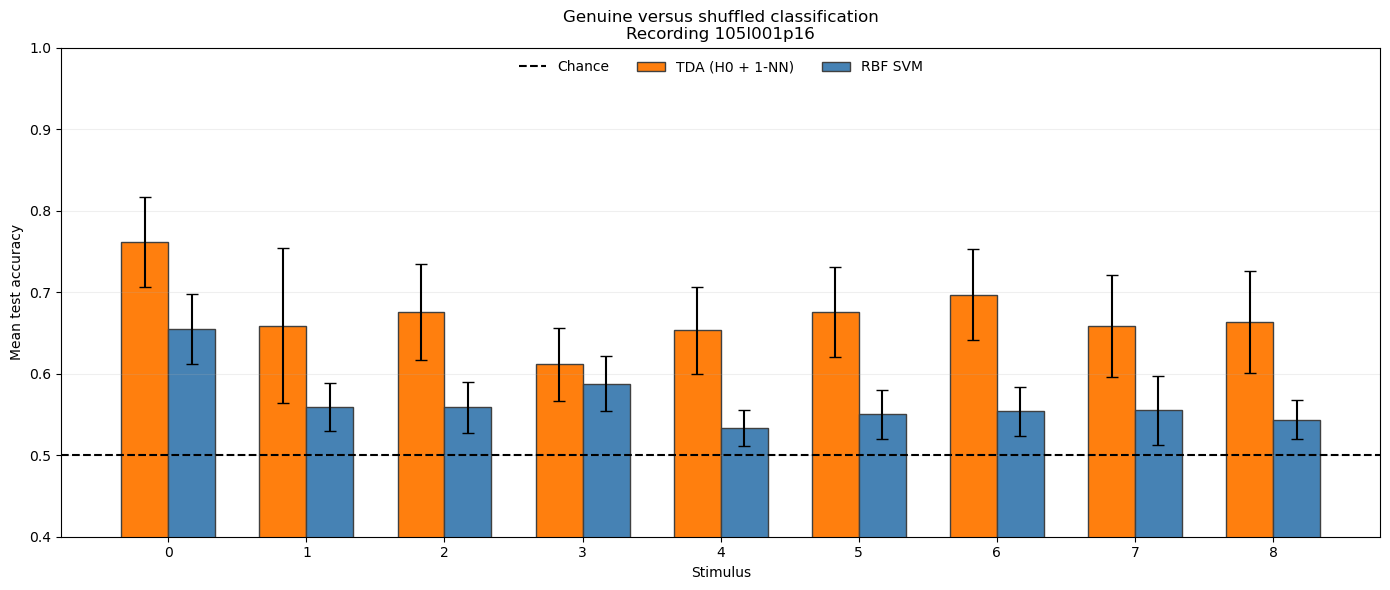

Saved: Results_Coordination_test/results_105l001p16/105l001p16_genuine_vs_shuffled_classification.pdf


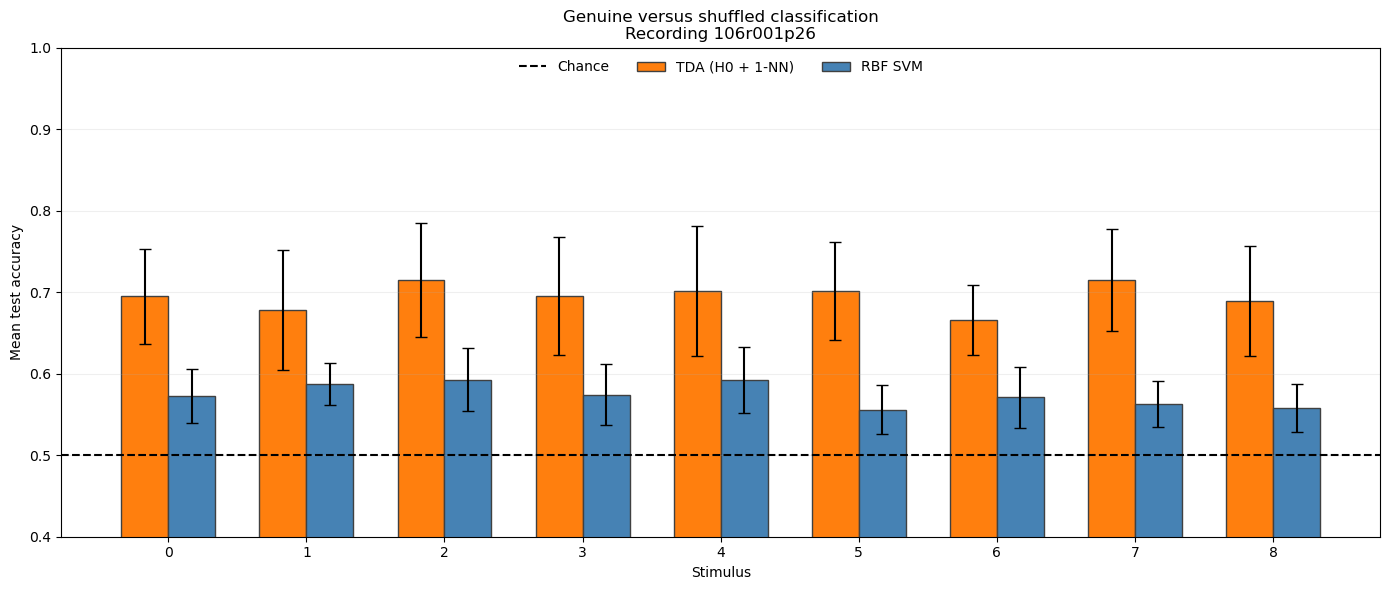

Saved: Results_Coordination_test/results_106r001p26/106r001p26_genuine_vs_shuffled_classification.pdf


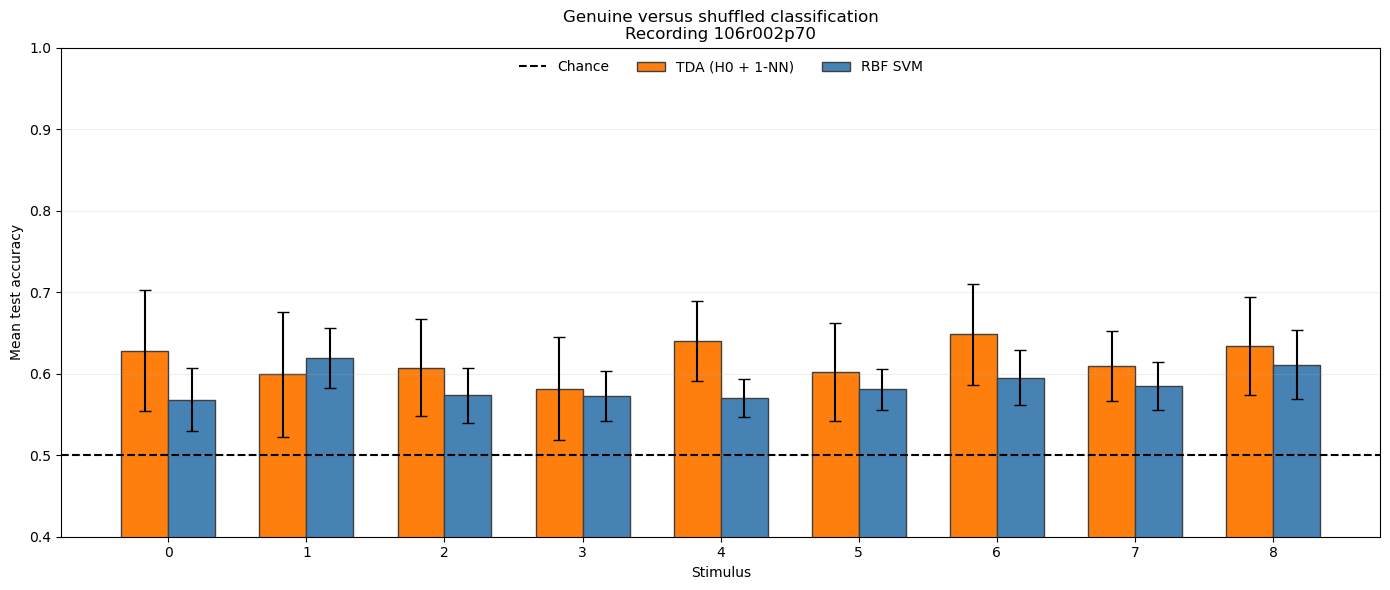

Saved: Results_Coordination_test/results_106r002p70/106r002p70_genuine_vs_shuffled_classification.pdf


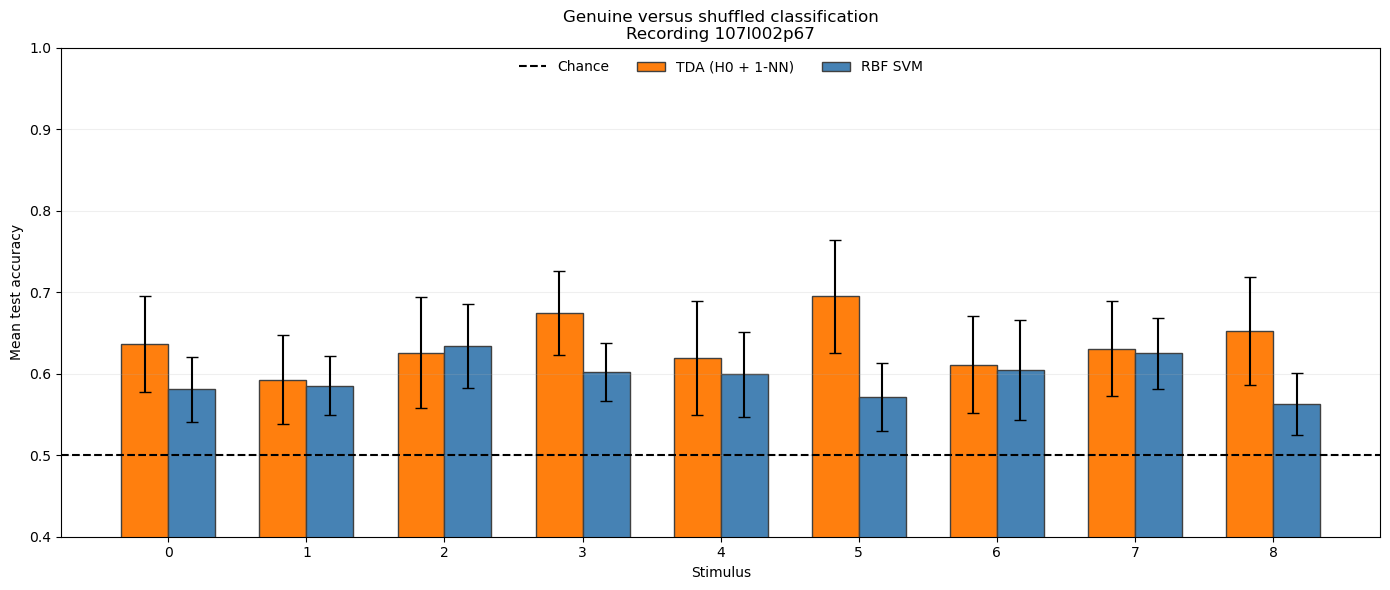

Saved: Results_Coordination_test/results_107l002p67/107l002p67_genuine_vs_shuffled_classification.pdf


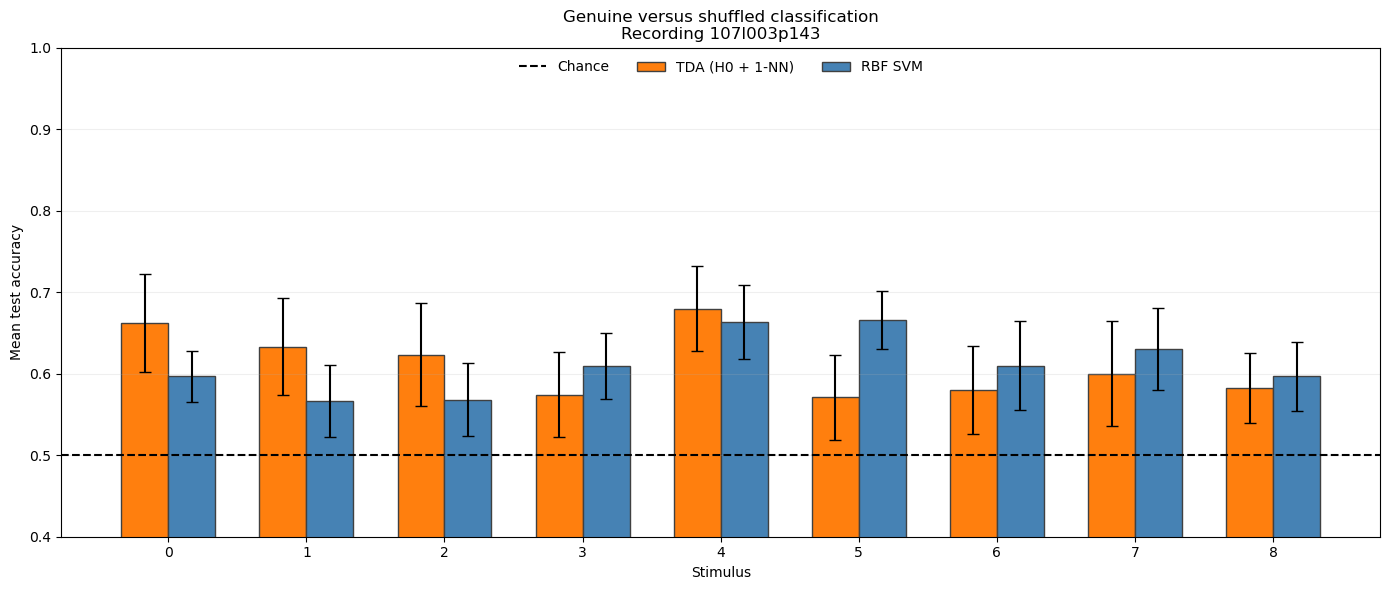

Saved: Results_Coordination_test/results_107l003p143/107l003p143_genuine_vs_shuffled_classification.pdf


In [51]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

base_directory = Path("Results_Coordination_test")

session_names = [
    "105l001p16",
    "106r001p26",
    "106r002p70",
    "107l002p67",
    "107l003p143",
]

for session_name in session_names:
    summary_key = f"{session_name}_all_stimuli_summary"
    summary = loaded_results[session_name][summary_key]
    summary = summary.sort_values("stimulus")

    stimuli = summary["stimulus"].to_numpy()
    tda_means = summary["tda_mean_accuracy"].to_numpy()
    tda_stds = summary["tda_std_accuracy"].to_numpy()
    svm_means = summary["rbf_svm_mean_accuracy"].to_numpy()
    svm_stds = summary["rbf_svm_std_accuracy"].to_numpy()
    chance = summary["chance_accuracy"].mean()

    positions = np.arange(len(stimuli))
    bar_width = 0.34

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.axhline(
        chance,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Chance",
    )

    ax.bar(
        positions - bar_width / 2,
        tda_means,
        width=bar_width,
        yerr=tda_stds,
        capsize=4,
        color="tab:orange",
        edgecolor="0.25",
        label="TDA (H0 + 1-NN)",
    )

    ax.bar(
        positions + bar_width / 2,
        svm_means,
        width=bar_width,
        yerr=svm_stds,
        capsize=4,
        color="steelblue",
        edgecolor="0.25",
        label="RBF SVM",
    )

    ax.set_title(
        f"Genuine versus shuffled classification\n"
        f"Recording {session_name}"
    )
    ax.set_xlabel("Stimulus")
    ax.set_ylabel("Mean test accuracy")
    ax.set_xticks(positions, stimuli)
    ax.set_ylim(0.4, 1.0)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="upper center", ncol=3, frameon=False)

    fig.tight_layout()

    output_directory = base_directory / f"results_{session_name}"
    output_directory.mkdir(parents=True, exist_ok=True)

    output_file = (
        output_directory
        / f"{session_name}_genuine_vs_shuffled_classification.pdf"
    )
    fig.savefig(output_file, format="pdf", bbox_inches="tight")
    plt.show(fig)

    print(f"Saved: {output_file}")

# Mean over 9 stimuli for each session

In [104]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_directory = Path("Results_Coordination_test")

session_names = [
    "105l001p16",
    "106r001p26",
    "106r002p70",
    "107l002p67",
    "107l003p143",
]

session_level_results = []

# Calculate mean and SEM across the nine stimuli.
for session_name in session_names:
    summary_key = f"{session_name}_all_stimuli_summary"
    summary = loaded_results[session_name][summary_key]

    tda_values = summary["tda_mean_accuracy"].to_numpy()
    svm_values = summary["rbf_svm_mean_accuracy"].to_numpy()

    session_level_results.append({
        "session": session_name,
        "n_stimuli": len(summary),
        "tda_mean": np.mean(tda_values),
        "tda_sem": np.std(tda_values, ddof=1) / np.sqrt(len(tda_values)),
        "rbf_svm_mean": np.mean(svm_values),
        "rbf_svm_sem": np.std(svm_values, ddof=1) / np.sqrt(len(svm_values)),
        "chance": summary["chance_accuracy"].mean(),
    })

results_df = pd.DataFrame(session_level_results)

# Display the numerical results.
display(
    results_df.round({
        "tda_mean": 4,
        "tda_sem": 4,
        "rbf_svm_mean": 4,
        "rbf_svm_sem": 4,
        "chance": 4,
    })
)

,session,n_stimuli,tda_mean,tda_sem,rbf_svm_mean,rbf_svm_sem,chance
0,105l001p16,9,0.6729,0.0135,0.5663,0.0121,0.5
1,106r001p26,9,0.6953,0.0053,0.5741,0.0047,0.5
2,106r002p70,9,0.6168,0.0073,0.5861,0.0062,0.5
3,107l002p67,9,0.6375,0.0106,0.5961,0.0079,0.5
4,107l003p143,9,0.6119,0.0134,0.6119,0.0120,0.5


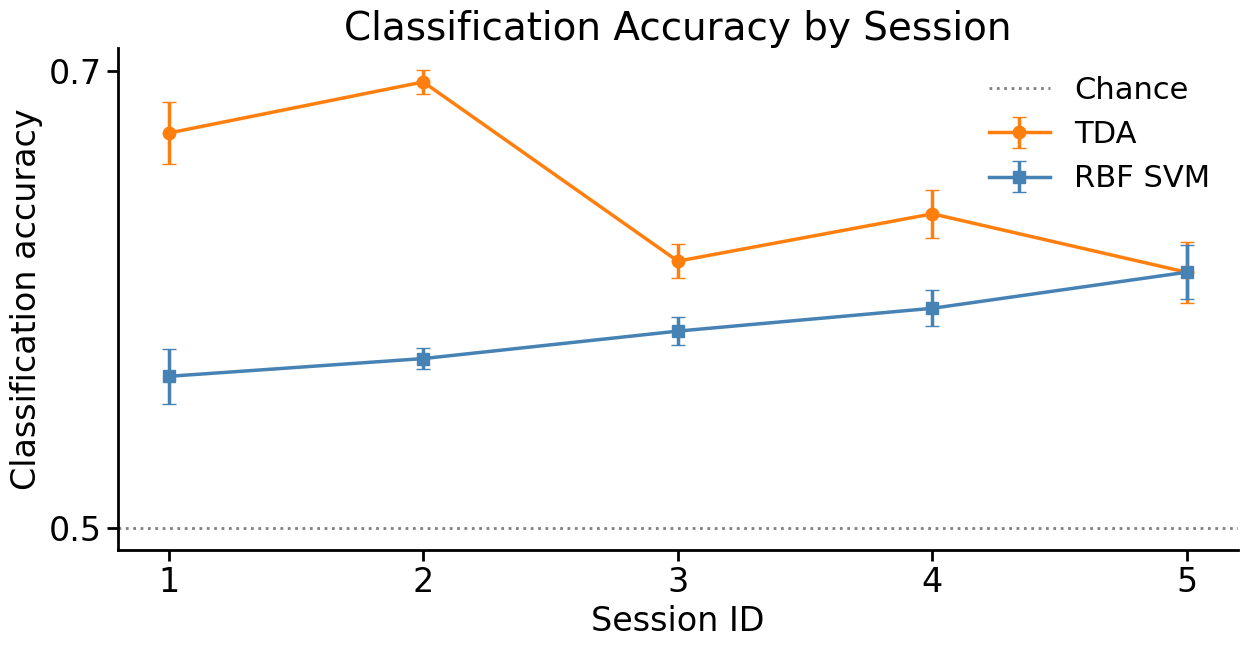

Saved: Results_Coordination_test/classification_accuracy_by_session.pdf


In [107]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 24,
    "axes.titlesize": 28,
    "axes.labelsize": 24,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
    "legend.fontsize": 22,
    "figure.titlesize": 28,
})



positions = np.arange(len(results_df))

fig, ax = plt.subplots(figsize=(13, 7))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep and optionally thicken the x- and y-axis lines.
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)

# Make tick marks larger and thicker.
ax.tick_params(axis="both", width=2, length=8)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.bottom": True,
    "axes.spines.left": True,
})

ax.axhline(
    results_df["chance"].mean(),
    color="gray",
    linestyle=":",
    linewidth=2,
    label="Chance",
)

ax.errorbar(
    positions,
    results_df["tda_mean"],
    yerr=results_df["tda_sem"],
    color="tab:orange",
    marker="o",
    markersize=9,
    linewidth=2.5,
    capsize=5,
    label="TDA",
)

ax.errorbar(
    positions,
    results_df["rbf_svm_mean"],
    yerr=results_df["rbf_svm_sem"],
    color="steelblue",
    marker="s",
    markersize=8,
    linewidth=2.5,
    capsize=5,
    label="RBF SVM",
)

ax.set_title(
    "Classification Accuracy by Session"
)

ax.set_xlabel("Session ID")
ax.set_ylabel("Classification accuracy")

ax.set_xticks(positions)
# ax.set_xticklabels(
#     results_df["session"],
#     rotation=30,
#     ha="right",
# )
ax.set_xticklabels([1,2,3,4,5])

ax.set_ylim(0.49, 0.71)
ax.set_yticks([0.5,0.7])
ax.grid(False)
ax.legend(loc="upper right", frameon=False)

fig.tight_layout()

output_file = base_directory / "classification_accuracy_by_session.pdf"
fig.savefig(output_file, format="pdf", bbox_inches="tight")

plt.show()

print(f"Saved: {output_file}")

In [70]:
session_id_mapping = results_df[["session"]].copy()

session_id_mapping.insert(
    0,
    "Session ID",
    range(1, len(session_id_mapping) + 1),
)

session_id_mapping = session_id_mapping.rename(
    columns={"session": "Session name"}
)

print(session_id_mapping.to_string(index=False))

 Session ID Session name
          1   105l001p16
          2   106r001p26
          3   106r002p70
          4   107l002p67
          5  107l003p143


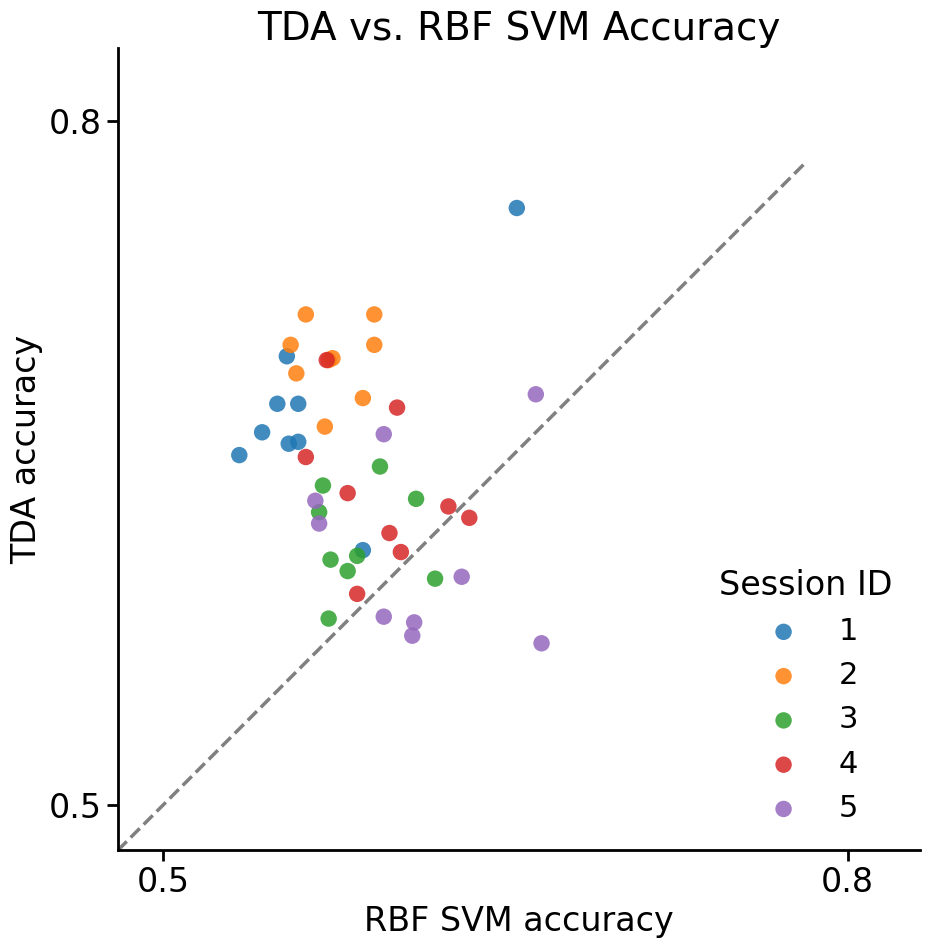

Saved: Results_Coordination_test/paired_tda_vs_rbf_svm_accuracy.pdf


In [109]:
base_directory = Path("Results_Coordination_test")

session_names = [
    "105l001p16",
    "106r001p26",
    "106r002p70",
    "107l002p67",
    "107l003p143",
]

# Universal formatting
plt.rcParams.update({
    "font.size": 24,
    "axes.titlesize": 28,
    "axes.labelsize": 24,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
    "legend.fontsize": 22,
    "figure.titlesize": 28,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


# Combine all session–stimulus results.
plot_data = []

for session_id, session_name in enumerate(session_names, start=1):
    summary_key = f"{session_name}_all_stimuli_summary"
    summary = loaded_results[session_name][summary_key].copy()

    for _, row in summary.iterrows():
        plot_data.append({
            "session_id": session_id,
            "session_name": session_name,
            "stimulus": row["stimulus"],
            "tda_accuracy": row["tda_mean_accuracy"],
            "rbf_svm_accuracy": row["rbf_svm_mean_accuracy"],
        })

plot_df = pd.DataFrame(plot_data)

# Count paired results in which TDA performed better.
tda_higher = (
    plot_df["tda_accuracy"] > plot_df["rbf_svm_accuracy"]
).sum()
total_pairs = len(plot_df)

# Plot
fig, ax = plt.subplots(figsize=(10,10))

colors = plt.cm.tab10(np.arange(len(session_names)))

for session_id, color in zip(
    range(1, len(session_names) + 1),
    colors,
):
    session_data = plot_df[
        plot_df["session_id"] == session_id
    ]

    ax.scatter(
        session_data["rbf_svm_accuracy"],
        session_data["tda_accuracy"],
        s=140,
        color=color,
        alpha=0.85,
        edgecolor="none",
        label=str(session_id),
    )

# Set common limits for both axes.
all_values = np.concatenate([
    plot_df["rbf_svm_accuracy"].to_numpy(),
    plot_df["tda_accuracy"].to_numpy(),
])

lower_limit = min(0.48, all_values.min() - 0.02)
upper_limit = max(0.78, all_values.max() + 0.02)

ax.set_xlim(lower_limit, upper_limit+0.05)
ax.set_ylim(lower_limit, upper_limit+0.05)
ax.set_xticks([0.5,0.8])
ax.set_yticks([0.5,0.8])

# Equality line: TDA accuracy = RBF SVM accuracy.
ax.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color="gray",
    linestyle="--",
    linewidth=2.5,
    zorder=0,
)

# ax.text(
#     0.04,
#     0.96,
#     f"TDA higher in {tda_higher}/{total_pairs} pairs",
#     transform=ax.transAxes,
#     ha="left",
#     va="top",
#     fontsize=21,
# )

ax.set_title("TDA vs. RBF SVM Accuracy")
ax.set_xlabel("RBF SVM accuracy")
ax.set_ylabel("TDA accuracy")

# Remove grid and retain only x/y axis lines.
ax.grid(False)
ax.spines["left"].set_linewidth(2)
ax.spines["bottom"].set_linewidth(2)
ax.tick_params(axis="both", width=2, length=8)

# Equal scaling on both axes.
ax.set_aspect("equal", adjustable="box")

ax.legend(
    title="Session ID",
    loc="lower right",
    frameon=False,
)

fig.tight_layout()

output_file = (
    base_directory
    / "paired_tda_vs_rbf_svm_accuracy.pdf"
)
fig.savefig(output_file, format="pdf", bbox_inches="tight")

plt.show()

print(f"Saved: {output_file}")